# EDA RuReviews — Егор Белехов

Цель: исследовать исходные отзывы о женской одежде и аксессуарах, выявить проблемы качества и подготовить рекомендации для отбора новых отзывов и независимой разметки.

Источник: [RuReviews](https://github.com/sismetanin/rureviews), файл `women-clothing-accessories.3-class.balanced.csv`. Локальные описание и лицензия находятся в `data/raw/rureviews/README.md` и `LICENSE`. Согласно описанию, метки получены автоматически из пользовательских оценок; балансированная версия сформирована undersampling. Метки источника не считаем проверенной ручной разметкой.

Для воспроизведения установите зависимости из `requirements.txt`, поместите исходный CSV в `data/raw/rureviews/` и выполните Restart Kernel → Run All. Запуск поддерживается из корня проекта и папки `notebooks`. Исходные данные не изменяются.


In [2]:
from pathlib import Path
import hashlib
import platform
import sys
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", None)
SEED = 17
ORDER = ["negative", "neutral", "positive"]
root = Path.cwd()
if not (root / "data/raw/rureviews").is_dir():
    root = root.parent
path = root / "data/raw/rureviews/women-clothing-accessories.3-class.balanced.csv"
if not path.is_file():
    raise FileNotFoundError(f"Поместите исходный RuReviews CSV в {path}")
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "seaborn:", sns.__version__, "matplotlib:", matplotlib.__version__)
print("Файл:", path.name)
print("SHA256:", hashlib.sha256(path.read_bytes()).hexdigest())
df = pd.read_csv(path, sep="\t")
assert {"review", "sentiment"}.issubset(df.columns)
print("Размер:", df.shape)
display(df.head())


Python: 3.13.12
pandas: 3.1.1 seaborn: 0.13.2 matplotlib: 3.11.2
Файл: women-clothing-accessories.3-class.balanced.csv
SHA256: db226708d966a1506560136ef85b33ea326eaf6119465d4b1edb5bf9395330fd
Размер: (90000, 2)


,review,sentiment
0,качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стоит за такие деньги г.......,negative
1,"Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.",negative
2,"Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На картинке кажется приталенной на самом деле нет! Не рекомендую",negative
3,"товар не пришел, продавец продлил защиту без моего согласия. от продавца одни обещания",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


## 1. Структура и классы

`review` — исходный текст отзыва; `sentiment` — автоматическая метка источника. Проверяем фактические значения до преобразований. Опечатку `neautral` приводим к `neutral` только в рабочей копии; исходный `df` сохраняем.


In [3]:
df.info()
display(df["sentiment"].value_counts(dropna=False).rename("count").to_frame())
work = df.copy()
work["sentiment"] = work["sentiment"].replace({"neautral": "neutral"})
unexpected = set(work["sentiment"].dropna().unique()) - set(ORDER)
assert not unexpected, f"Неизвестные метки: {unexpected}"
class_counts = work["sentiment"].value_counts().reindex(ORDER, fill_value=0)
display(pd.DataFrame({"count": class_counts, "percent": (class_counts / len(work) * 100).round(2)}))
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=work, x="sentiment", order=ORDER, ax=ax)
ax.set(title="Исходное распределение классов", xlabel="Класс", ylabel="Число отзывов")
plt.show()


AttributeError: module 'numpy' has no attribute 'matrix'

## 2. Пропуски, пустые тексты и точные дубликаты

Пустой текст — строка, пустая после удаления краевых пробелов, либо пропуск. Бессодержательность ниже оценивается лишь техническим признаком отсутствия букв и цифр: это не полная семантическая проверка. Число дубликатов с `keep='first'` обозначает лишние вхождения, а не число уникальных повторяющихся текстов.


In [ ]:
text = work["review"].fillna("")
empty = text.str.strip().eq("")
has_alnum = text.str.contains(r"[A-Za-zА-Яа-яЁё0-9]", regex=True)
punctuation_only = ~has_alnum & ~empty
conflict_counts = work.groupby("review", dropna=True)["sentiment"].nunique()
conflict_texts = conflict_counts[conflict_counts > 1].index
conflict_mask = work["review"].isin(conflict_texts)
quality = pd.Series({
    "Пропуски review": work["review"].isna().sum(),
    "Пропуски sentiment": work["sentiment"].isna().sum(),
    "Пустые тексты (включая пропуски)": empty.sum(),
    "Непустые тексты без букв/цифр": punctuation_only.sum(),
    "Лишние полные дубликаты строк": df.duplicated().sum(),
    "Лишние точные повторы текста": work["review"].duplicated().sum(),
    "Уникальные повторяющиеся тексты": work.loc[work["review"].duplicated(keep=False), "review"].nunique(),
    "Уникальные тексты с конфликтом классов": len(conflict_texts),
    "Строки с конфликтующими текстами": conflict_mask.sum(),
}, name="count")
display(quality.to_frame())
display(work.loc[empty])
display(text.value_counts().head(15).rename_axis("review").rename("count").to_frame())


,count
Пропуски review,0
Пропуски sentiment,0
Пустые тексты (включая пропуски),1
Непустые тексты без букв/цифр,129
Лишние полные дубликаты строк,2250
Лишние точные повторы текста,2679
Уникальные повторяющиеся тексты,945
Уникальные тексты с конфликтом классов,388
Строки с конфликтующими текстами,2045


,review,sentiment
81917,,positive


,count
review,
Товар не пришёл,58
товар не пришел,55
.,46
"товар не пришел, деньги вернули",43
супер,40
отлично,34
Товар не пришел,33
"Товар не пришёл, деньги вернули",32
ок,29


## 3. Конфликтующие метки: количество и примеры

Чтобы не делать вывод по первым отсортированным знакам препинания, отдельно считаем уникальные конфликтующие тексты с буквами/цифрами и без них. Для просмотра используем фиксированную случайную выборку содержательных конфликтов. Наличие букв не гарантирует однозначной тональности.


In [ ]:
conflict_table = (work.loc[conflict_mask].groupby("review")
    .agg(labels=("sentiment", lambda s: ", ".join(sorted(s.unique()))), occurrences=("sentiment", "size"))
    .reset_index())
conflict_table["has_letters_or_digits"] = conflict_table["review"].str.contains(r"[A-Za-zА-Яа-яЁё0-9]", regex=True)
conflict_summary = conflict_table.groupby("has_letters_or_digits").agg(
    unique_texts=("review", "size"), rows=("occurrences", "sum"))
display(conflict_summary)
meaningful_conflicts = conflict_table[conflict_table["has_letters_or_digits"]]
display(meaningful_conflicts.sample(n=min(12, len(meaningful_conflicts)), random_state=SEED))
display(conflict_table[~conflict_table["has_letters_or_digits"]].head(10))


,unique_texts,rows
has_letters_or_digits,,
False,7,86
True,381,1959


,review,labels,occurrences,has_letters_or_digits
306,плохо,"negative, neutral",11,True
106,"Переднюю часть фото описывают неплохо, а вот задней картинка явно польстила. Там лоскутик гораздо меньше","negative, neutral",2,True
232,заказ не пришёл но деньги вернули,"negative, neutral",2,True
145,"Товар не пришел, деньги вернули.","negative, neutral",4,True
368,товар не пришёл. деньги вернули.,"negative, neutral",4,True
208,все норм,"neutral, positive",4,True
375,торчат нитки,"neutral, positive",4,True
149,"Товар не пришел, продавец вернул деньги.","negative, neutral, positive",5,True
180,Товар не пришёл. Деньги вернули,"negative, neutral, positive",7,True
71,Не пришло,"negative, neutral",7,True


,review,labels,occurrences,has_letters_or_digits
0,!,"neutral, positive",4,False
1,!!!,"negative, neutral",2,False
2,-,"negative, neutral",13,False
3,.,"negative, neutral, positive",46,False
4,..,"negative, neutral",4,False
5,...,"negative, neutral, positive",15,False
7,:(,"negative, neutral",2,False


## 4. Длина отзывов

Длина в символах считается по исходному тексту, в словах — по разбиению на пробельные символы (это не лингвистическая токенизация). Статистика включает пустые тексты. Для наглядности гистограмма ограничена 99-м перцентилем; длинный хвост остаётся в таблице и boxplot показан без выбросов.


,n_chars,n_words
count,90000.00,90000.00
mean,130.07,20.01
std,126.14,19.89
min,1.00,0.00
1%,7.00,1.00
25%,51.00,8.00
50%,91.00,14.00
75%,164.00,25.00
95%,372.00,58.00
99%,648.00,102.00


n_chars                      n_words                   
              min median    mean   max     min median   mean  max
sentiment                                                        
negative        1   99.0  144.68  1007       1   15.0  22.46  192
neutral         1   86.0  125.81  1000       1   13.0  19.59  193
positive        1   89.0  119.72  1004       0   13.0  17.98  174

Отзывы не длиннее 2 слов: 3877


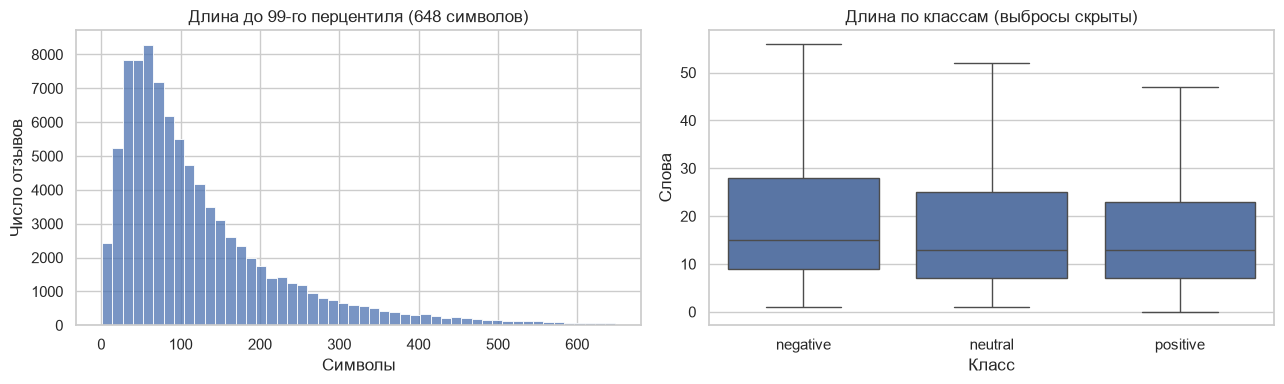

,review,sentiment,n_chars,n_words
2817,"Качество шубы просто отвратительное. Вся шуба дырявая, швы пошиты как попало, черными нитками розовая шуба! Линяет ужасно! На розовой замше красными нитками нарисовано! Замшу видно! Крючки отваливаются, и пришиты тяп ляп. (Кстати уже отдала 1800 чтобы перешить крючки!) \r\nМеха мало и он жидкий, линяет ппц! Сроду такого позора мехового не видела!\r\nПродавец и размер посоветовал не верный, мне большая! Пришлось внахлест перешивать крючки!\r\nОткрыла спор, али не одобрил возврат 6000 на ремонт шубы, говорят отправьте обратно! Обратно? Серьёзно? И платить пересыл? Подала жалобу на возврат 6000, жду пересмотра спора! \r\nЦена шубе 8000 не больше! На один сезон шуба и то если носить раз в неделю, сыпется жутко,вся вылезет!\r\nПродавцу написала что шуба вся бракованная, молчит! Даже не извинился! И не предложил решить вопрос!\r\nЕсли али не одобрит жалобу я буду просто в шоке! Отпишусь тут по результатам. \r\nШУБУ НЕ СОВЕТУЮ! НЕ ТРАТЬТЕ ДЕНЬГИ! Прийдет лысая и драная! Лучше доплатить 5000 и купить качественную!",negative,1007,153
8286,"Продавец мутный, не отправлял заказ больше недели после оформления! Мы брали платную доставку в 700 руб. Через 2 месяца с большими проблемами выбивали свой заказ в курьерской службе. Нам объяснили, что доставку продавец не хотел оплачивать службе, товар лежал у них мертвым грузом.. \r\nЦвет куртки мне прислали другой, я открыла спор, но денег до сих пор не увидела.\r\nЭтот продавец мутный, все время переспрашивает, типа не понимает языка, в то время, как весь мир пользуется онлайн-переводчиком. \r\nВ общем, отвратительная сделка и отстойный продавец, абсолютно безответственный и не желающий что-то менять. Не рекомендовала бы заказывать у него даже своим врагам- нервов потратят больше, к тому же отморозят задницу. В России зима уже 2 месяца идет так-то!\r\nБесплатные посылки заказываю уже 2 года на Али Экспресс, платную попробовала впервые и такой результат. \r\nУважаемый продавец, обращаюсь к тебе: НАУЧИСЬ ПОЛЬЗОВАТЬСЯ ОНЛАЙН-ПЕРЕВОДЧИКОМ. Гугл тебе в помощь! Хотя сомневаюсь, что и он тебе поможет...",negative,1005,149
25253,"Крайне разочарована покупкой, не понимаю, почему столько восторженных отзывов.\r\r\nЗаказ я делала быстро, не рассматривала фото в отзывах, а зря. В описании футболки все картинки были с подворотами - это и была моя цель. А по факту это мужская футболка, скроена не на женскую фигуру, и к тому же очень плохого качества.\r\r\nФутболка сверху болтается, под мышками пузыри, а внизу обтягивает очень сильно. Если на даче я одену футболку моего мужа получается примерно то же. И длина значительно ниже положенного, опять же по мужскому типу футболки. То есть, продавец просто взял мужскую модель, прилепил к ней лапки наклейки и выдал её за женскую. А на женскую фигуру, понятно, она не садится.\r\r\nТеперь о качестве. Футболка не хлопковая. Конечно присутствует какое-то количество хлопковой нити, но большая часть синтетика. Торчат нитки, швы не ровные.\r\r\nФутболка своих денег не стоит, по качеству она должна стоить половину суммы.\r\r\nЯ довольна много заказываю на алиэкспресс трикотаж, пока эта покупка худшая.",negative,1004,155


In [ ]:
work["n_chars"] = text.str.len()
work["n_words"] = text.str.split().str.len()
display(work[["n_chars", "n_words"]].describe(percentiles=[.01, .25, .5, .75, .95, .99]).round(2))
display(work.groupby("sentiment")[["n_chars", "n_words"]].agg(["min", "median", "mean", "max"]).reindex(ORDER).round(2))
print("Отзывы не длиннее 2 слов:", int(work["n_words"].le(2).sum()))
limit = work["n_chars"].quantile(.99)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=work[work["n_chars"] <= limit], x="n_chars", bins=50, ax=axes[0])
axes[0].set(title=f"Длина до 99-го перцентиля ({limit:.0f} символов)", xlabel="Символы", ylabel="Число отзывов")
sns.boxplot(data=work, x="sentiment", y="n_words", order=ORDER, showfliers=False, ax=axes[1])
axes[1].set(title="Длина по классам (выбросы скрыты)", xlabel="Класс", ylabel="Слова")
plt.tight_layout()
plt.show()
display(work.nlargest(3, "n_chars")[["review", "sentiment", "n_chars", "n_words"]])


## 5. Неоднозначные случаи для codebook

Ниже реальные примеры, найденные прозрачными эвристиками. Это подборка для ручного просмотра, а не автоматическое определение тональности. Метки источника могут быть ошибочными. Наличие «но» не всегда означает смешанную оценку, а признаки иронии не доказывают сарказм.


In [ ]:
example_rules = {
    "Смешанная оценка / противопоставление": r"\bно\b|\bзато\b|\bоднако\b",
    "Доставка / получение": r"достав|не приш[её]л|не получил|деньги вернул",
    "Возможная ирония (требует проверки)": r"спасибо.{0,50}(?:\bне\b|ужас|дыр|брак)|отличн.{0,50}(?:\bне\b|ужас|дыр|брак)",
}
for title, pattern in example_rules.items():
    candidates = work[text.str.contains(pattern, case=False, regex=True)].drop_duplicates("review")
    display(Markdown(f"### {title}: {len(candidates)} уникальных кандидатов"))
    display(candidates.sample(n=min(4, len(candidates)), random_state=SEED)[["review", "sentiment"]])
display(Markdown("### Короткие содержательные отзывы"))
short = work[has_alnum & work["n_words"].between(1, 2)].drop_duplicates("review")
display(short.sample(n=min(8, len(short)), random_state=SEED)[["review", "sentiment"]])


### Смешанная оценка / противопоставление: 21369 уникальных кандидатов

,review,sentiment
41063,"На российский 48 размер была заказана L.Товар пришел.На пакете действительно стоит маркировка L.А вот на самом изделии нет вообще никаких маркировок.На меня он просто не налез.Зато идиально,прямо как на фото,сел на мою дочь,которая носит 42 размер и весит 50 кило при росте 164.Вот сижу и думаю:то ли вещь так нереально маломерит,то ли мне просто в пакет положили другой размер..",neutral
8364,"Порвались сразу после первой же примерки, морщинятся, пррдавец вроде как сначала был готов сделать частичный возврат,, потом пропал как то. Не хотела спор открывать, но придется наверное теперь",negative
73799,"Продавец общительный и отзывчивый, отвечал на все вопросы, но к сожалению товар не пришел, и это минус нашей почте. Продавцу спасибо за честность , деньги вернул.",positive
35809,"приятная к телу очень. топ хороший, но штаны на рост 174 короткие, но носить как приджи можно, перед и зад у них сшит одинаково, у кого бедра 100 и более, не советую хл даже будет мал, если у вас достаточно большой обьем сзади, будут малы, тк одинаково и спереди и сзади.",neutral


### Доставка / получение: 18690 уникальных кандидатов

,review,sentiment
85763,"Доставка 10 дней. Ткань сплошная синтетика. Качество отличное, сшито аккуратно. На объем бедер 100 М село отлично",positive
85359,отличные брюки всё хорошо быстрая доставка спасибо большое продавцу,positive
62909,"Доставка 20 дней. Для такой цены качество нормальное. Размеры указаны на стрвнице товара очень странно-длина,ширина трусов...Указанные длину,ширину сравнила со своими, предположила, что подойдут. Увы...Больше по такой ""размерной шкале"" покупать не буду. Надеть то надела, но если буду двигаться, садиться в них, то треснут швы там, где отверстия для ног, они не очень растягиваются.",positive
2327,После 4 месяцев ожидания товар так и не получили открыл спор вернули деньги,negative


### Возможная ирония (требует проверки): 1167 уникальных кандидатов

,review,sentiment
78607,"Кофточка просто замечательная ! Приятный материал ,без зАпаха, рукава длинные,даже не похоже на алиэкспресс в этом плане)))на мой 42-44 и рост 168 см села отлично! Не короткая , тянется . Спасибо продавцу ' буду заказывать ещё в других цветах !",positive
58874,"размер XL на рост 163 и вес 57 очень маленький, сидит ужасно, хотя подбирала по размерной сетке на 2размера с запасом, обидно конечно, а продавец хороший, на все мои вопросы терпеливо отвечал, качество товара тоже отличное, никаких косяков не обнаружила. куртка на зиму думаю тоже подойдет, жаль что только с маечкой в её залезу)) товар за такие деньги просто шикарный, в магазинах такие 2500-3000р , заказывайте, только внимательнее с размерами, ужасно маломерят!! всем добра",neutral
13999,"с виду на первый взгляд юбка отличная. НО она не удобная, подюбник сшит не ровно и не аккуратно. когда ходишь юбка поднимается. короче только на вид красиво, а качество не очень.",negative
68854,"Платье пришло за 2 недели в г. Брянск, отслеживалось. В жизни ношу М, но по размерной сетке и совету продавца заказа XL, и не прогадала, в поясе, как пишут в других отщывах не торчит. Мои параметры ОГ 98, ОТ 76, ОБ- 98. Спасибо за красивое платье, пошито отлично. Заказывайте не пожалеете.",positive


### Короткие содержательные отзывы

,review,sentiment
53626,Неплохо,neutral
27354,Не хлопок!!!!,negative
46947,OK,neutral
18932,Ужасно,negative
87282,Симпатичная маечка.,positive
31014,не доставлены,neutral
81364,Очень классные,positive
42084,не рекомендую,neutral


Рекомендации для пробного codebook (требуют проверки на 10–15 заданиях с Никитой):

- **positive:** явная положительная оценка или удовлетворённость; **negative:** явное недовольство; **neutral:** описательный текст без выраженной оценки либо смешанная оценка без преобладающей стороны. Правило смешанных случаев согласовать до массовой разметки.
- **Смешанные отзывы:** учитывать итоговую позицию автора и существенность претензий, а не автоматически назначать класс по слову «но».
- **Доставка:** заранее определить объект оценки — вся покупка или только товар. Для общей оценки покупки «товар не пришёл» выражает отрицательный опыт; правила возврата денег и сочетаний с качеством товара требуют отдельного примера.
- **Сарказм:** учитывать смысл всей фразы, не отдельные положительные слова; спорные случаи отправлять на обсуждение после независимых экспортов. Эвристическая подборка выше сама по себе не подтверждает наличие сарказма.
- **Короткие отзывы:** «отлично» и «ужас» содержат оценку, поэтому длина сама по себе не причина отказа. «мало» требует контекста; звёзды для выбора итоговой метки не использовать.
- **Пустые и бессодержательные тексты:** отклонять при отборе, а не принудительно относить к neutral. Неоднозначные содержательные отзывы не удалять автоматически ради повышения согласия.


## 6. Иллюстрация консервативной очистки

Отдельная рабочая выборка: исключаем пустые строки и строки без букв/цифр, откладываем **все** тексты с конфликтующими метками для ручного разбора, затем оставляем по одному экземпляру остальных точных повторов. Это пример политики для исходного датасета, а не окончательная обучающая выборка. Цифровые или формально содержательные строки ещё нуждаются в просмотре. Исходный `df` и CSV не перезаписываются.


,rows
Исходные строки,90000
После фильтра пустых / без букв и цифр,89870
После откладывания конфликтующих текстов,87911
После удаления лишних точных повторов,86893


,original,clean,clean_percent
sentiment,,,
negative,30000,28894,33.25
neutral,30000,28725,33.06
positive,30000,29274,33.69


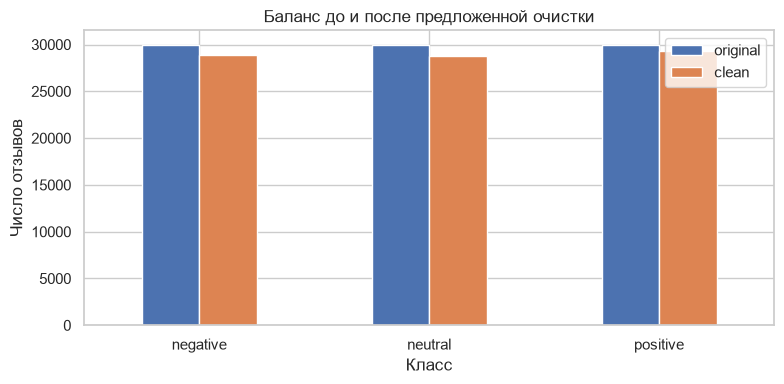

Проверки целостности рабочей выборки пройдены.


In [ ]:
valid_content = ~empty & has_alnum
eligible = work.loc[valid_content & ~conflict_mask].copy()
df_clean = eligible.drop_duplicates(subset="review", keep="first").copy()
stages = pd.Series({
    "Исходные строки": len(work),
    "После фильтра пустых / без букв и цифр": int(valid_content.sum()),
    "После откладывания конфликтующих текстов": len(eligible),
    "После удаления лишних точных повторов": len(df_clean),
}, name="rows")
display(stages.to_frame())
balance = pd.DataFrame({"original": class_counts, "clean": df_clean["sentiment"].value_counts().reindex(ORDER, fill_value=0)})
balance["clean_percent"] = (balance["clean"] / len(df_clean) * 100).round(2)
display(balance)
balance[["original", "clean"]].plot.bar(figsize=(8, 4), rot=0)
plt.title("Баланс до и после предложенной очистки")
plt.xlabel("Класс")
plt.ylabel("Число отзывов")
plt.tight_layout()
plt.show()
assert df_clean["review"].is_unique
assert not df_clean["review"].isin(conflict_texts).any()
assert len(df) == len(work)
print("Проверки целостности рабочей выборки пройдены.")


## 7. Выводы по выполненным расчётам


In [ ]:
n_conf_alnum = int(conflict_table["has_letters_or_digits"].sum())
n_conf_non_alnum = len(conflict_table) - n_conf_alnum
display(Markdown(f"""
1. **Объём и классы:** {len(df):,} строк, {df.shape[1]} исходных столбца; размеры классов: {class_counts.to_dict()}. Баланс получен отбором в источнике и не отражает частоты отзывов в реальности. Он не гарантирует отсутствие смещения метрик.
2. **Качество:** пропуски текста — {int(work['review'].isna().sum())}; пустые тексты — {int(empty.sum())}; непустые тексты без букв/цифр — {int(punctuation_only.sum())}. Лишних полных повторов строк — {int(df.duplicated().sum())}, лишних точных повторов текста — {int(work['review'].duplicated().sum())}.
3. **Метки:** у {len(conflict_table)} уникальных текстов конфликтуют классы. Из них {n_conf_alnum} содержат буквы/цифры, {n_conf_non_alnum} не содержат. Поэтому противоречия нельзя объяснить только знаками препинания. Возможны шум автоматической разметки и зависимость оценки от отсутствующего контекста; конкретные причины по CSV установить нельзя.
4. **Длины:** медиана — {work['n_chars'].median():.0f} символов / {work['n_words'].median():.0f} слов; 99-й перцентиль — {work['n_chars'].quantile(.99):.0f} символов; максимум — {work['n_chars'].max()} символов. Короткие фразы требуют отдельного правила, длинные — просмотра целиком.
5. **Очистка:** после предложенных фильтров остаётся {len(df_clean):,} строк. Новый баланс показан выше. Исключение конфликтов может сделать задачу легче и изменить состав выборки; это решение нужно фиксировать в протоколе эксперимента.
6. **Новые данные:** собирать минимум 50 принятых отзывов каждого класса с запасом; проверять пустоту, содержательность и повторы. Предварительные классы и звёзды использовать только для отбора кандидатов, не показывать при независимой разметке.
7. **Codebook:** согласовать объект оценки (товар/вся покупка), смешанные отзывы, короткие фразы и сарказм; проверить правила на 10–15 пробных заданиях. Сохранить две независимые разметки, затем обсуждать расхождения.
8. **Ограничения:** проверены точные повторы; различия регистра, пробелов, орфографии, почти одинаковые отзывы и семантические дубликаты здесь не устранены. Перед обучением группировать одинаковые/близкие тексты при разбиении, чтобы уменьшить риск утечки между train/test. WB — отдельный источник, поэтому результаты этого EDA нельзя автоматически переносить на новые отзывы.
"""))



1. **Объём и классы:** 90,000 строк, 2 исходных столбца; размеры классов: {'negative': 30000, 'neutral': 30000, 'positive': 30000}. Баланс получен отбором в источнике и не отражает частоты отзывов в реальности. Он не гарантирует отсутствие смещения метрик.
2. **Качество:** пропуски текста — 0; пустые тексты — 1; непустые тексты без букв/цифр — 129. Лишних полных повторов строк — 2250, лишних точных повторов текста — 2679.
3. **Метки:** у 388 уникальных текстов конфликтуют классы. Из них 381 содержат буквы/цифры, 7 не содержат. Поэтому противоречия нельзя объяснить только знаками препинания. Возможны шум автоматической разметки и зависимость оценки от отсутствующего контекста; конкретные причины по CSV установить нельзя.
4. **Длины:** медиана — 91 символов / 14 слов; 99-й перцентиль — 648 символов; максимум — 1007 символов. Короткие фразы требуют отдельного правила, длинные — просмотра целиком.
5. **Очистка:** после предложенных фильтров остаётся 86,893 строк. Новый баланс показан выше. Исключение конфликтов может сделать задачу легче и изменить состав выборки; это решение нужно фиксировать в протоколе эксперимента.
6. **Новые данные:** собирать минимум 50 принятых отзывов каждого класса с запасом; проверять пустоту, содержательность и повторы. Предварительные классы и звёзды использовать только для отбора кандидатов, не показывать при независимой разметке.
7. **Codebook:** согласовать объект оценки (товар/вся покупка), смешанные отзывы, короткие фразы и сарказм; проверить правила на 10–15 пробных заданиях. Сохранить две независимые разметки, затем обсуждать расхождения.
8. **Ограничения:** проверены точные повторы; различия регистра, пробелов, орфографии, почти одинаковые отзывы и семантические дубликаты здесь не устранены. Перед обучением группировать одинаковые/близкие тексты при разбиении, чтобы уменьшить риск утечки между train/test. WB — отдельный источник, поэтому результаты этого EDA нельзя автоматически переносить на новые отзывы.
